<a href="https://colab.research.google.com/github/cmburban/MAT-422/blob/main/MAT422_Section_3_4_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 - Section 3.4: Logistic Regression

Topics: Sigmoid/logistic function, Binary classification probabilities, Logistic regression fitting and interpretation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=4, suppress=True)

## 3.4.1 Sigmoid/Logistic Function

The sigmoid function converts any real number into a value between 0 and 1. Logistic regression uses this function to estimate the probability that an observation belongs to a particular class.

The sigmoid function is defined as:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

In this equation, \(z\) is the input value and \(e\) is the mathematical constant used in the exponential function.

When \(z = 0\), the sigmoid function returns 0.5. Positive inputs produce probabilities greater than 0.5, while negative inputs produce probabilities less than 0.5.

I will calculate the sigmoid function for several input values and graph its shape to see how the output changes.

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Test the sigmoid function with several input values
z_values = np.array([-6, -3, -1, 0, 1, 3, 6])
sigmoid_values = sigmoid(z_values)

print("Input values:", z_values)
print("Sigmoid outputs:", sigmoid_values)

# Verify important properties
print("\nOutput at z = 0:", sigmoid(0))
print("All outputs are between 0 and 1:",
      np.all((sigmoid_values > 0) & (sigmoid_values < 1)))
print("Output at z = 0.0 is 0.5:",
      np.isclose(sigmoid(0), 0.5))

Input values: [-6 -3 -1  0  1  3  6]
Sigmoid outputs: [0.0025 0.0474 0.2689 0.5    0.7311 0.9526 0.9975]

Output at z = 0: 0.5
All outputs are between 0 and 1: True
Output at z = 0.0 is 0.5: True


### Visualizing the Sigmoid Function

A graph makes it easier to understand how the sigmoid function transforms its input. I will plot the function over a wider range of values to show how its output approaches 0 for negative inputs and 1 for positive inputs.

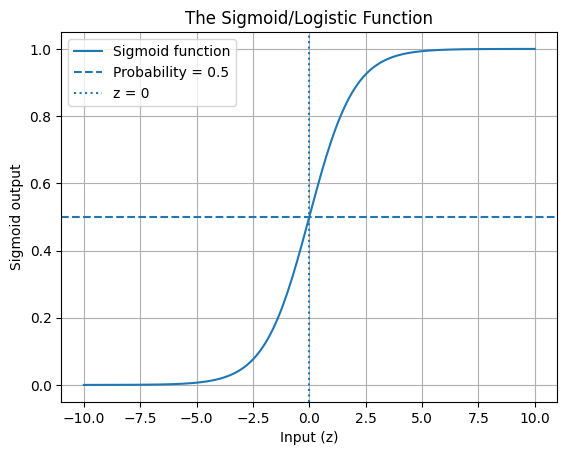

In [3]:
z_values = np.linspace(-10, 10, 200)
sigmoid_values = sigmoid(z_values)

plt.plot(z_values, sigmoid_values, label="Sigmoid function")
plt.axhline(y=0.5, linestyle="--", label="Probability = 0.5")
plt.axvline(x=0, linestyle=":", label="z = 0")

plt.xlabel("Input (z)")
plt.ylabel("Sigmoid output")
plt.title("The Sigmoid/Logistic Function")
plt.legend()
plt.grid(True)

plt.show()

### Interpretation

The numerical results show that the sigmoid function always produces values between 0 and 1. When the input is zero, the output is exactly 0.5. The graph has an S-shaped curve, approaching 0 for large negative inputs and 1 for large positive inputs. These properties make the sigmoid function useful for representing probabilities in logistic regression.

## 3.4.2 Binary Classification Probabilities

Logistic regression is commonly used for binary classification, where each observation belongs to one of two classes, labeled 0 and 1. Instead of immediately predicting a class, logistic regression estimates the probability that an observation belongs to class 1.

A probability closer to 0 indicates a greater likelihood of class 0, while a probability closer to 1 indicates a greater likelihood of class 1.

To convert probabilities into class predictions, we can use a threshold of 0.5:
- If the probability is greater than or equal to 0.5, predict class 1.
- If the probability is less than 0.5, predict class 0.

I will use example probabilities to demonstrate how this threshold converts probabilities into predicted classes.

In [4]:
# Example probabilities predicted by a logistic regression model
probabilities = np.array([0.15, 0.35, 0.50, 0.80, 0.92])

# Convert probabilities into class predictions using a 0.5 threshold
predicted_classes = (probabilities >= 0.5).astype(int)

print("Predicted probabilities:", probabilities)
print("Predicted classes:      ", predicted_classes)

# Display each probability alongside its predicted class
print("\nProbability -> Predicted class")
for probability, predicted_class in zip(probabilities, predicted_classes):
    print(f"{probability:.2f} -> {predicted_class}")

# Verify that probabilities below 0.5 map to class 0
# and probabilities at or above 0.5 map to class 1
print("\nThreshold verification:",
      np.array_equal(predicted_classes, np.array([0, 0, 1, 1, 1])))

Predicted probabilities: [0.15 0.35 0.5  0.8  0.92]
Predicted classes:       [0 0 1 1 1]

Probability -> Predicted class
0.15 -> 0
0.35 -> 0
0.50 -> 1
0.80 -> 1
0.92 -> 1

Threshold verification: True


### Interpretation

The results demonstrate how a probability threshold of 0.5 converts estimated probabilities into binary class predictions. Probabilities below 0.5 are classified as class 0, while probabilities equal to or greater than 0.5 are classified as class 1. The threshold verification returns `True`, confirming that the predictions follow the specified rule. These example probabilities illustrate the classification process; they are not predictions from a trained model.

## 3.4.3 Logistic Regression Fitting and Interpretation

Logistic regression learns the relationship between input features and a binary outcome using labeled training data. During training, the model estimates coefficients and an intercept that help it calculate the probability that an observation belongs to class 1.

After fitting the model, we can use it to predict probabilities and classify new observations. We can also evaluate its performance by comparing predicted classes with the actual labels.

In this example, I will use a small dataset with one numerical feature and a binary outcome. I will train a logistic regression model, examine its coefficients and predictions, calculate its accuracy, and graph the predicted probabilities.

In [5]:
# Create a small, reproducible dataset
# X represents a numerical input feature
X = np.array([
    [1], [2], [3], [4], [5], [6],
    [7], [8], [9], [10], [11], [12]
])

# y represents the actual binary class labels
y = np.array([0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1])

# Train the logistic regression model
model = LogisticRegression()
model.fit(X, y)

# Generate probabilities and class predictions
probabilities_class_1 = model.predict_proba(X)[:, 1]
predicted_classes = model.predict(X)

# Display the model's learned parameters
print("Model coefficient:", model.coef_[0][0])
print("Model intercept:", model.intercept_[0])

# Display actual labels, probabilities, and predictions
print("\nFeature | Actual class | Probability of class 1 | Predicted class")
for feature, actual, probability, prediction in zip(
    X[:, 0], y, probabilities_class_1, predicted_classes
):
    print(f"{feature:7} | {actual:12} | {probability:22.4f} | {prediction:15}")

# Evaluate the model
accuracy = accuracy_score(y, predicted_classes)
print(f"\nTraining accuracy: {accuracy:.2%}")
print("\nConfusion matrix:")
print(confusion_matrix(y, predicted_classes))

Model coefficient: 0.7506847760167801
Model intercept: -4.879636597716645

Feature | Actual class | Probability of class 1 | Predicted class
      1 |            0 |                 0.0158 |               0
      2 |            0 |                 0.0330 |               0
      3 |            0 |                 0.0674 |               0
      4 |            0 |                 0.1327 |               0
      5 |            1 |                 0.2449 |               0
      6 |            0 |                 0.4072 |               0
      7 |            0 |                 0.5927 |               1
      8 |            1 |                 0.7551 |               1
      9 |            1 |                 0.8672 |               1
     10 |            1 |                 0.9326 |               1
     11 |            1 |                 0.9670 |               1
     12 |            1 |                 0.9841 |               1

Training accuracy: 83.33%

Confusion matrix:
[[5 1]
 [1 5]]


### Visualizing the Logistic Regression Model

A graph helps us understand how logistic regression connects input values to predicted probabilities. The scatter points represent the actual class labels, while the curve represents the probabilities estimated by the trained model.

The horizontal line at 0.5 represents the classification threshold. Input values with predicted probabilities at or above this threshold are classified as class 1, while values below it are classified as class 0.

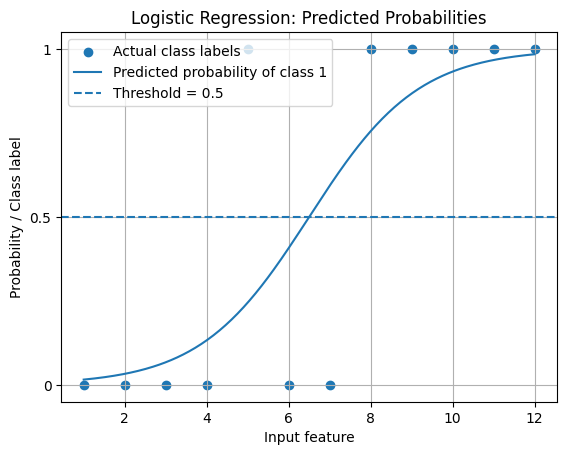

In [6]:
# Generate a smooth range of input values for the curve
X_curve = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

# Calculate the probability of class 1 for each input value
probability_curve = model.predict_proba(X_curve)[:, 1]

# Plot the actual class labels
plt.scatter(X[:, 0], y, label="Actual class labels")

# Plot the logistic regression probability curve
plt.plot(
    X_curve[:, 0],
    probability_curve,
    label="Predicted probability of class 1"
)

# Add the classification threshold
plt.axhline(y=0.5, linestyle="--", label="Threshold = 0.5")

plt.xlabel("Input feature")
plt.ylabel("Probability / Class label")
plt.title("Logistic Regression: Predicted Probabilities")
plt.yticks([0, 0.5, 1], ["0", "0.5", "1"])
plt.legend()
plt.grid(True)

plt.show()

### Interpretation

The trained logistic regression model estimates the probability that each observation belongs to class 1 based on its numerical input feature. The model's coefficient describes how the feature affects the predicted log-odds of class 1, while the intercept determines the baseline of the model.

The graph shows how the predicted probability changes as the input feature increases. The horizontal line at 0.5 represents the decision threshold used to classify observations into class 0 or class 1. The training accuracy and confusion matrix provide numerical checks of the model's performance on the training data. Because the model is evaluated on the same data used to train it, this accuracy does not necessarily represent how well it will perform on new observations.

## End of Notebook Reflection

In this section, I learned how logistic regression uses the sigmoid function to convert numerical inputs into probabilities between 0 and 1. I explored how a classification threshold of 0.5 converts probabilities into binary predictions and how logistic regression can be trained using labeled data. I also examined the model's coefficients, predicted probabilities, accuracy, confusion matrix, and probability curve. These examples helped me understand how logistic regression can be used to solve binary classification problems and evaluate prediction results.

## References

[Mathematical Methods in Data Science - Elsevier (2023)](https://doi.org/10.1016/B978-0-44-318679-0.00007-7)

[Numpy - Singular Value Decomposition](https://numpy.org/doc/stable/reference/generated/numpy.linalg.svd.html)

[Matplotlib](https://matplotlib.org/stable/)

[Scikit-learn Developers](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)


[OpenAI - ChatGPT (2026)](https://chatgpt.com)

## Submission Checklist

- I explained each concept in words before or after the code. [DONE]
- I verified important claims numerically or visually. [DONE]
- I changed or extended at least one example so the notebook reflects my own work. [DONE]
- I ran the notebook from top to bottom without errors. [DONE]
- I saved the notebook from Google Colab directly to GitHub, following the course instructions. [DONE]